In [35]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import KFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

In [36]:
np.random.seed(42)

# Load data csv
dataFolder = Path("./data").absolute()
resultsFolder = Path("./results").absolute()
plotsFolder = Path("./plots").absolute()
data = pd.read_csv(dataFolder / "final_data.csv")
latex = True  # Set to True to use LaTeX rendering for text in plots

In [39]:
def train_test_split(X, y, test_size=0.2, random_state=42, splitColumn=None):
    if splitColumn is not None and splitColumn in X.columns:
        # If a split column is provided, use it to split the data (each unique element of that column must appear only in either train or test set)
        unique_values = X[splitColumn].unique()
        np.random.shuffle(unique_values)
        split_index = int(len(unique_values) * (1 - test_size))
        train_values = unique_values[:split_index]
        test_values = unique_values[split_index:]
        
        X_train = X[X[splitColumn].isin(train_values)].drop(columns=[splitColumn])
        y_train = y[X[splitColumn].isin(train_values)]
        X_test = X[X[splitColumn].isin(test_values)].drop(columns=[splitColumn])
        y_test = y[X[splitColumn].isin(test_values)]
    else:
        # If no split column is provided, use random splitting
        from sklearn.model_selection import train_test_split as sk_train_test_split
        X_train, X_test, y_train, y_test = sk_train_test_split(X, y, test_size=test_size, random_state=random_state)
    
    return X_train, X_test, y_train, y_test

def k_fold_cv(X, y, k=5, random_state=42, splitColumn=None):
    if splitColumn is not None and splitColumn in X.columns:
        unique_values = X[splitColumn].unique()
        np.random.shuffle(unique_values)
        fold_size = len(unique_values) // k
        folds = [unique_values[i*fold_size:(i+1)*fold_size] for i in range(k)]
        
        for i in range(k):
            test_values = folds[i]
            train_values = np.concatenate([folds[j] for j in range(k) if j != i])
            
            X_train = X[X[splitColumn].isin(train_values)].drop(columns=[splitColumn])
            y_train = y[X[splitColumn].isin(train_values)]
            X_test = X[X[splitColumn].isin(test_values)].drop(columns=[splitColumn])
            y_test = y[X[splitColumn].isin(test_values)]
            
            yield X_train, y_train, X_test, y_test
    else:
        from sklearn.model_selection import KFold
        kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
        for train_index, test_index in kf.split(X):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]
            yield X_train, y_train, X_test, y_test

def _apply_latex_rcparams() -> None:
    # NOTE: This does not validate that a LaTeX distribution is installed.
    # If missing, matplotlib will raise at render/save time.
    plt.rcParams.update(
        {
            "text.usetex": True,
            "font.family": "serif",
            # Use LaTeX fonts instead of matplotlib rcfonts.
            "pgf.rcfonts": False,
            "pgf.texsystem": "pdflatex",
        }
    )

In [4]:
time_window_widths = [(0,1), (1,2), (2,3), (3,4), (4,5)]

maitain_it_features = [False, True]

classifiers = {
    "NB": MultinomialNB(),
    "MLP": MLPClassifier(random_state=42, max_iter=300),
    "KNN": KNeighborsClassifier(n_jobs=-1),
    "DT": DecisionTreeClassifier(random_state=42),
    "RFC": RandomForestClassifier(random_state=42, n_jobs=-1)
}
scores = pd.DataFrame(columns=["Classifier", "Time Window", "Fold", "Precision", "Recall", "F1-Score", "Maintain IT Features"])

In [ ]:
for maintain_it in maitain_it_features:
    if not maintain_it:
        print("Training classifiers without IT features...")
        data_working = data.drop(columns=["setpoint-count", "average-delay"])
    else:
        print("Training classifiers with IT features...")
        data_working = data.copy()
    for w in time_window_widths:
        start = w[0]
        end = w[1]
        # Consider the samples belonging to the training window
        data_window = data_working[(data_working["t-from-trip"] >= start) & (data_working["t-from-trip"] < end)]
        print(f"Training classifiers on data from the first {w} seconds of the simulation...")
        # Split the data into features and target variable
        X = data_window.drop("class", axis=1)  # Features
        y = data_window["class"]  # Target variable

        for clfName, clf in classifiers.items():
            print(f"Training and evaluating {clfName} on data from the first {w} seconds of the simulation...")
            for fold, (X_train, y_train, X_test, y_test) in enumerate(k_fold_cv(X, y, k=5, random_state=42, splitColumn="run-id")):
                print(f"Fold {fold + 1}")
                clf.fit(X_train, y_train)
                # Make predictions
                y_pred = clf.predict(X_test)
                
                # Evaluate the model
                report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
                # The time window is reported in absolute time and not relative to the trip event (for consistency with the previous plots)
                scores = pd.concat([scores, pd.DataFrame({
                    "Classifier": clfName,
                    "Time Window": f"{start+1}-{end+1} seconds",
                    "Fold": fold + 1,
                    "Precision": report["weighted avg"]["precision"],
                    "Recall": report["weighted avg"]["recall"],
                    "F1-Score": report["weighted avg"]["f1-score"],
                    "Maintain IT Features": maintain_it
                }, index=[0])], ignore_index=True)
scores.to_csv(resultsFolder / "classifier_scores.csv", index=False)

Training classifiers without IT features...
Training classifiers on data from the first (0, 1) seconds of the simulation...
Training and evaluating NB on data from the first (0, 1) seconds of the simulation...
Fold 1
Fold 2
Fold 3
Fold 4


/tmp/ipykernel_4159970/998316325.py:29: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  scores = pd.concat([scores, pd.DataFrame({


Fold 5
Training and evaluating MLP on data from the first (0, 1) seconds of the simulation...
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
Training and evaluating KNN on data from the first (0, 1) seconds of the simulation...
Fold 1


/home/davide.savarro/co-simulation/.venv/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:788: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


Fold 2
Fold 3
Fold 4
Fold 5
Training and evaluating DT on data from the first (0, 1) seconds of the simulation...
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
Training and evaluating RFC on data from the first (0, 1) seconds of the simulation...
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
Training classifiers on data from the first (1, 2) seconds of the simulation...
Training and evaluating NB on data from the first (1, 2) seconds of the simulation...
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
Training and evaluating MLP on data from the first (1, 2) seconds of the simulation...
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
Training and evaluating KNN on data from the first (1, 2) seconds of the simulation...
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
Training and evaluating DT on data from the first (1, 2) seconds of the simulation...
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
Training and evaluating RFC on data from the first (1, 2) seconds of the simulation...
Fold 1
Fold 2
Fold 3
Fold 4
Fold 5
Training classifiers on data from the fir

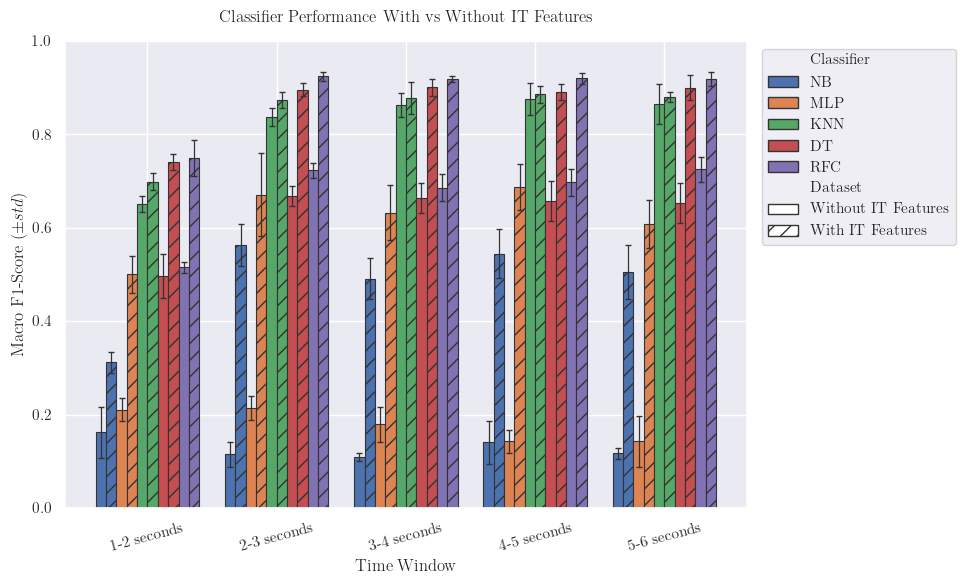

In [52]:
scores = pd.read_csv(resultsFolder / "classifier_scores.csv")
sns.set_theme() # Apply this before potentially setting latex rcParams, so that seaborn's style is preserved

if latex:
    try:
        # Prefer a LaTeX-native backend.
        plt.use("pgf")
    except Exception:
        # Backend switch can fail in some environments; keep going with default backend.
        pass
    try:
        _apply_latex_rcparams()
    except Exception:
        # Fall back to default rcParams; we can still try to enable usetex later.
        pass

# Add a condition column for plotting
scores["Condition"] = scores["Maintain IT Features"].apply(
    lambda x: "With IT Features" if x else "Without IT Features"
)

# Keep time windows in chronological order (e.g., 1-2, 2-3, ...)
time_windows = sorted(
    scores["Time Window"].unique(),
    key=lambda s: int(str(s).split("-")[0])
)

# Enforce classifier order from left to right in each time-window cluster
desired_order = ["NB", "MLP", "KNN", "DT", "RFC"]
classifiers_present = set(scores["Classifier"].unique())
classifiers_list = [clf for clf in desired_order if clf in classifiers_present]

conditions = ["Without IT Features", "With IT Features"]

# Visual mapping: same color per classifier, different hatches per condition
colors_map = {
    clf: color
    for clf, color in zip(classifiers_list, sns.color_palette(n_colors=len(classifiers_list)))
}
hatches = {"Without IT Features": "", "With IT Features": "//"}

fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=False)

x_centers = np.arange(len(time_windows))
n_classifiers = len(classifiers_list)
n_conditions = len(conditions)

# Keep bars intentionally small within each time-window group
group_width = 0.80
bar_width = group_width / (n_classifiers * n_conditions)

for c_idx, clf in enumerate(classifiers_list):
    clf_data = scores[scores["Classifier"] == clf]
    summary = (
        clf_data.groupby(["Time Window", "Condition"])["F1-Score"]
        .agg(["mean", "std"])
        .reset_index()
    )

    for k_idx, condition in enumerate(conditions):
        cond_summary = summary[summary["Condition"] == condition].set_index("Time Window")
        cond_summary = cond_summary.reindex(time_windows)

        # Position each bar in a compact cluster around the time-window center
        local_index = c_idx * n_conditions + k_idx
        offset = -group_width / 2 + (local_index + 0.5) * bar_width

        ax.bar(
            x_centers + offset,
            cond_summary["mean"],
            width=bar_width,
            color=colors_map[clf],
            hatch=hatches[condition],
            edgecolor=".2",
            linewidth=0.8,
            yerr=cond_summary["std"],
            capsize=2,
            error_kw={"ecolor": ".2", "elinewidth": 0.9},
        )

ax.set_title("Classifier Performance With vs Without IT Features", pad=14)
ax.set_xlabel("Time Window")
if not latex: ax.set_ylabel("Macro F1-Score (± std)") 
else: ax.set_ylabel("Macro F1-Score $(\pm std$)")  
ax.set_ylim(0, 1.0)
ax.set_xticks(x_centers)
ax.set_xticklabels(time_windows, rotation=15)

# Single legend box with section headers for classifiers and dataset conditions
legend_handles = [
    Patch(facecolor="none", edgecolor="none", label="Classifier"),
]
legend_handles += [
    Patch(facecolor=colors_map[clf], edgecolor=".2", label=clf)
    for clf in classifiers_list
]
legend_handles += [
    Patch(facecolor="none", edgecolor="none", label="Dataset"),
]
legend_handles += [
    Patch(facecolor="white", edgecolor=".2", hatch=hatches[cond], label=cond)
    for cond in conditions
]

ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(1.01, 1.00),
    frameon=True,
    ncol=1,
)

# Reserve room on the right for legend
plt.tight_layout(rect=[0, 0, 0.82, 1])
plt.savefig(plotsFolder / "classifier_comparison.pdf", bbox_inches="tight")